# Uso, procesamiento y visualización de grandes volúmenes de datos
## Predicción de retrasos en vuelos de EE.UU. con PySpark

Emilio López

**Link a repositorio de github**: https://github.com/EmilioQuinonez/VACAS_IA/tree/main

### Datos
Usé los datos de puntualidad de vuelos del Bureau of Transportation Statistics (BTS) del gobierno de EE.UU. (https://www.transtats.bts.gov). Tomé todo 2023, que son 12 archivos (uno por mes), con 6,847,899 vuelos y casi 3 GB en CSV.

## 1. Configuración de PySpark
Instalo PySpark y creo la sesión de Spark. Le asigno 8 GB de memoria porque Colab gratis tiene alrededor de 12 GB.

In [2]:
!pip install -q pyspark

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("RetrasosVuelos")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())

print("Versión de Spark:", spark.version)
spark

Versión de Spark: 4.0.5


## 2. Descarga de los datos
BTS tiene un zip por mes. Aquí los descargo directo en Colab y los descomprimo, así no tengo que bajar nada a mi computadora. Tarda unos minutos.

In [4]:
import os, urllib.request, zipfile

os.makedirs("/content/data", exist_ok=True)
url_base = "https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2023_{}.zip"

for mes in range(1, 13):
    ruta_zip = f"/content/data/2023_{mes}.zip"
    print(f"Descargando mes {mes}...")
    urllib.request.urlretrieve(url_base.format(mes), ruta_zip)
    with zipfile.ZipFile(ruta_zip) as z:
        csv = [n for n in z.namelist() if n.endswith(".csv")][0]
        z.extract(csv, "/content/data")
    os.remove(ruta_zip)   # borramos el zip para ahorrar disco

!ls -lh /content/data
!du -sh /content/data

Descargando mes 1...
Descargando mes 2...
Descargando mes 3...
Descargando mes 4...
Descargando mes 5...
Descargando mes 6...
Descargando mes 7...
Descargando mes 8...
Descargando mes 9...
Descargando mes 10...
Descargando mes 11...
Descargando mes 12...
total 2.9G
-rw-r--r-- 1 root root 259M Nov 22 00:33 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_10.csv'
-rw-r--r-- 1 root root 244M Nov 22 00:33 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_11.csv'
-rw-r--r-- 1 root root 247M Nov 22 00:33 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_12.csv'
-rw-r--r-- 1 root root 233M Nov 22 00:29 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_1.csv'
-rw-r--r-- 1 root root 217M Nov 22 00:30 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_2.csv'
-rw-r--r-- 1 root root 251M Nov 22 00:30 'On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2023_3.csv'
-rw-r--r-- 1 root root 242M Nov 22 00:31 

### Lectura con Spark
Leo los 12 CSV de una vez. Los archivos traen 110 columnas, pero solo me quedo con las que voy a usar y les pongo su tipo correcto, porque vienen como texto.

In [5]:
df_raw = spark.read.csv("/content/data/*.csv", header=True)

df = df_raw.select(
    F.col("Month").cast("int"),
    F.col("DayofMonth").cast("int"),
    F.col("DayOfWeek").cast("int"),          # 1 = lunes ... 7 = domingo
    F.col("Reporting_Airline"),               # código de aerolínea
    F.col("Origin"), F.col("OriginCityName"),
    F.col("Dest"),
    F.col("CRSDepTime").cast("int"),          # hora programada de salida (hhmm)
    F.col("Distance").cast("double"),
    F.col("ArrDelay").cast("double"),         # minutos de retraso en llegada
    F.col("ArrDel15").cast("double"),         # 1 si llegó con >= 15 min de retraso
    F.col("Cancelled").cast("double"),
    F.col("Diverted").cast("double"),
    F.col("CarrierDelay").cast("double"),
    F.col("WeatherDelay").cast("double"),
    F.col("NASDelay").cast("double"),
    F.col("SecurityDelay").cast("double"),
    F.col("LateAircraftDelay").cast("double"),
)

df.printSchema()
print("Total de vuelos:", df.count())

root
 |-- Month: integer (nullable = true)
 |-- DayofMonth: integer (nullable = true)
 |-- DayOfWeek: integer (nullable = true)
 |-- Reporting_Airline: string (nullable = true)
 |-- Origin: string (nullable = true)
 |-- OriginCityName: string (nullable = true)
 |-- Dest: string (nullable = true)
 |-- CRSDepTime: integer (nullable = true)
 |-- Distance: double (nullable = true)
 |-- ArrDelay: double (nullable = true)
 |-- ArrDel15: double (nullable = true)
 |-- Cancelled: double (nullable = true)
 |-- Diverted: double (nullable = true)
 |-- CarrierDelay: double (nullable = true)
 |-- WeatherDelay: double (nullable = true)
 |-- NASDelay: double (nullable = true)
 |-- SecurityDelay: double (nullable = true)
 |-- LateAircraftDelay: double (nullable = true)

Total de vuelos: 6847899


### Pasar a Parquet
Guardo los datos en formato Parquet, separados por mes. Parquet ocupa mucho menos que CSV y Spark lo lee más rápido. Abajo comparo el tamaño y el tiempo.

In [6]:
df.write.mode("overwrite").partitionBy("Month").parquet("/content/vuelos_parquet")

!du -sh /content/data
!du -sh /content/vuelos_parquet

vuelos = spark.read.parquet("/content/vuelos_parquet")
print("Vuelos leídos desde Parquet:", vuelos.count())

2.9G	/content/data
41M	/content/vuelos_parquet
Vuelos leídos desde Parquet: 6847899


In [7]:
import time

inicio = time.time()
df.groupBy("Reporting_Airline").count().collect()
print(f"Agrupación leyendo CSV:     {time.time() - inicio:.1f} s")

inicio = time.time()
vuelos.groupBy("Reporting_Airline").count().collect()
print(f"Agrupación leyendo Parquet: {time.time() - inicio:.1f} s")

Agrupación leyendo CSV:     35.2 s
Agrupación leyendo Parquet: 2.1 s


Los datos pasaron de 2.9 GB a 41 MB y la misma consulta bajó de 35.2 a 2.1 segundos, unas 17 veces más rápido. Hay que aclarar que parte de la reducción de tamaño es porque en Parquet solo guardé 18 de las 110 columnas.

## 3. Limpieza y análisis
Agrego la hora de salida (`DepHour`) y el nombre de cada aerolínea, porque en los datos solo viene su código.

In [8]:
aerolineas = spark.createDataFrame([
    ("9E", "Endeavor Air"), ("AA", "American Airlines"), ("AS", "Alaska Airlines"),
    ("B6", "JetBlue"), ("DL", "Delta Air Lines"), ("F9", "Frontier"),
    ("G4", "Allegiant Air"), ("HA", "Hawaiian Airlines"), ("MQ", "Envoy Air"),
    ("NK", "Spirit Airlines"), ("OH", "PSA Airlines"), ("OO", "SkyWest"),
    ("UA", "United Airlines"), ("WN", "Southwest Airlines"), ("YX", "Republic Airways"),
], ["Reporting_Airline", "Airline"])

vuelos = (vuelos
          .withColumn("DepHour", (F.floor(F.col("CRSDepTime") / 100) % 24).cast("int"))
          .join(F.broadcast(aerolineas), on="Reporting_Airline", how="left"))

vuelos.cache()
vuelos.show(5)

+-----------------+----------+---------+------+-------------------+----+----------+--------+--------+--------+---------+--------+------------+------------+--------+-------------+-----------------+-----+-------+---------------+
|Reporting_Airline|DayofMonth|DayOfWeek|Origin|     OriginCityName|Dest|CRSDepTime|Distance|ArrDelay|ArrDel15|Cancelled|Diverted|CarrierDelay|WeatherDelay|NASDelay|SecurityDelay|LateAircraftDelay|Month|DepHour|        Airline|
+-----------------+----------+---------+------+-------------------+----+----------+--------+--------+--------+---------+--------+------------+------------+--------+-------------+-----------------+-----+-------+---------------+
|               NK|        21|        1|   FLL|Fort Lauderdale, FL| SAT|      1305|  1145.0|     9.0|     0.0|      0.0|     0.0|        NULL|        NULL|    NULL|         NULL|             NULL|    8|     13|Spirit Airlines|
|               NK|        22|        2|   FLL|Fort Lauderdale, FL| SAT|      1659|  1145.0|

In [9]:
# Valores nulos por columna
vuelos.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in vuelos.columns]).show(vertical=True)

-RECORD 0--------------------
 Reporting_Airline | 0       
 DayofMonth        | 0       
 DayOfWeek         | 0       
 Origin            | 0       
 OriginCityName    | 0       
 Dest              | 0       
 CRSDepTime        | 0       
 Distance          | 0       
 ArrDelay          | 104496  
 ArrDel15          | 104496  
 Cancelled         | 0       
 Diverted          | 0       
 CarrierDelay      | 5461201 
 WeatherDelay      | 5461201 
 NASDelay          | 5461201 
 SecurityDelay     | 5461201 
 LateAircraftDelay | 5461201 
 Month             | 0       
 DepHour           | 0       
 Airline           | 0       



Los vuelos sin `ArrDelay` son los cancelados o desviados, porque nunca llegaron normal. Las columnas de causas solo se llenan cuando hubo retraso, por eso tienen tantos vacíos. Los cancelados y desviados los dejo para el tablero, pero no los uso en el modelo.

In [10]:
vuelos.select(
    F.count("*").alias("vuelos"),
    F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retrasados"),
    F.round(F.avg("Cancelled") * 100, 2).alias("pct_cancelados"),
    F.round(F.avg("Diverted") * 100, 2).alias("pct_desviados"),
    F.round(F.avg("ArrDelay"), 2).alias("retraso_promedio_min"),
).show()

+-------+--------------+--------------+-------------+--------------------+
| vuelos|pct_retrasados|pct_cancelados|pct_desviados|retraso_promedio_min|
+-------+--------------+--------------+-------------+--------------------+
|6847899|         20.56|          1.28|         0.24|                6.63|
+-------+--------------+--------------+-------------+--------------------+



En este punto podemos ver que el 20.56% de retraso se calcula solo con los 6,743,403 vuelos que sí llegaron a su destino, ya que `avg` no toma en cuenta los nulos. Los 104,496 vuelos cancelados o desviados no entran en ese porcentaje, por lo que los vuelos que tuvieron algún problema son un poco más de lo que indica este número.

In [11]:
# Porcentaje de vuelos retrasados por aerolínea
por_aerolinea = (vuelos.groupBy("Airline")
                 .agg(F.count("*").alias("vuelos"),
                      F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retraso"))
                 .orderBy(F.desc("pct_retraso")))
por_aerolinea.show()

+------------------+-------+-----------+
|           Airline| vuelos|pct_retraso|
+------------------+-------+-----------+
|          Frontier| 177542|      31.43|
|           JetBlue| 274852|      31.19|
|   Spirit Airlines| 263871|      29.14|
|     Allegiant Air| 115539|      25.91|
| Hawaiian Airlines|  80967|      23.74|
| American Airlines| 940531|      23.04|
|Southwest Airlines|1438465|      21.81|
|   United Airlines| 732212|      20.61|
|   Alaska Airlines| 245344|      19.64|
|         Envoy Air| 227488|      18.15|
|      PSA Airlines| 194144|      16.62|
|   Delta Air Lines| 984986|      16.37|
|           SkyWest| 675163|      16.26|
|      Endeavor Air| 201520|      13.92|
|  Republic Airways| 295275|      13.07|
+------------------+-------+-----------+



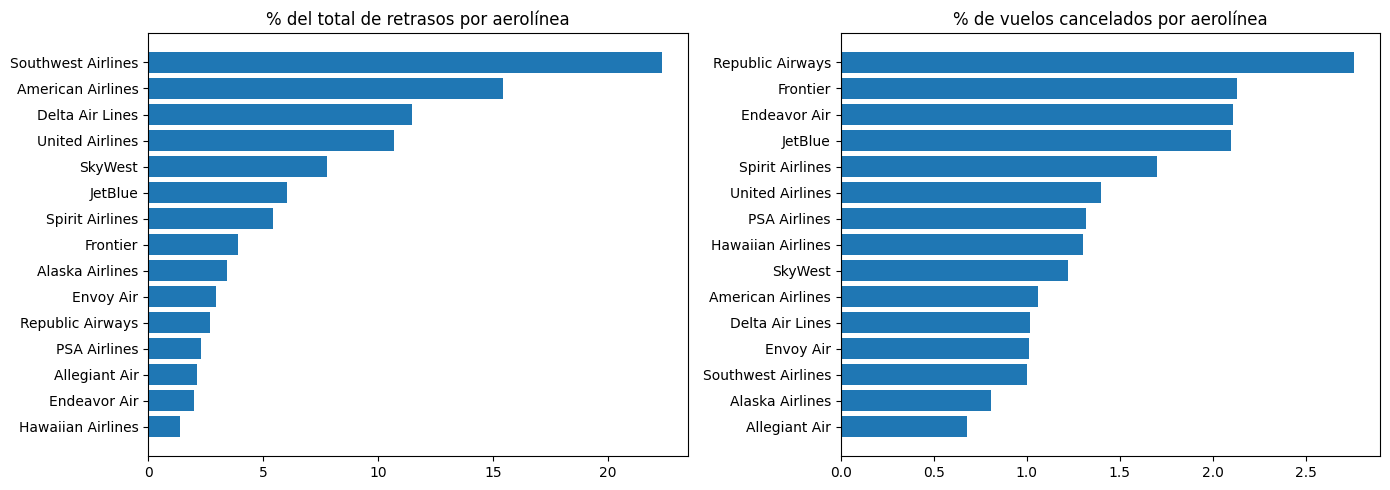

In [12]:
# Qué parte de los retrasos genera cada aerolínea y cuánto cancela
import matplotlib.pyplot as plt

pd_aero2 = (vuelos.groupBy("Airline")
            .agg(F.sum("ArrDel15").alias("retrasados"),
                 F.round(F.avg("Cancelled") * 100, 2).alias("pct_cancelados"))
            .toPandas())
pd_aero2["pct_del_total"] = pd_aero2["retrasados"] / pd_aero2["retrasados"].sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

orden = pd_aero2.sort_values("pct_del_total")
ax[0].barh(orden["Airline"], orden["pct_del_total"])
ax[0].set_title("% del total de retrasos por aerolínea")

orden = pd_aero2.sort_values("pct_cancelados")
ax[1].barh(orden["Airline"], orden["pct_cancelados"])
ax[1].set_title("% de vuelos cancelados por aerolínea")

plt.tight_layout()
plt.show()

En cuanto a las aerolíneas, podemos ver que Frontier es la que tiene el mayor porcentaje de retraso con 31.4%, sin embargo Southwest es la que más retrasos genera en total, con cerca del 22%, ya que opera muchos más vuelos que las demás. Esto nos indica que una mejora en Southwest tendría más impacto en el total que la misma mejora en Frontier.

Lo más interesante es Republic, ya que es la más puntual con 13.1%, pero también es la que más cancela con 2.76%. Como un vuelo cancelado no cuenta como retrasado, su puntualidad puede verse mejor de lo que realmente es.

In [13]:
# Porcentaje de retraso por hora de salida y por mes
por_hora = vuelos.groupBy("DepHour").agg(F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retraso")).orderBy("DepHour")
por_mes = vuelos.groupBy("Month").agg(F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retraso")).orderBy("Month")
por_hora.show(24)
por_mes.show()

+-------+-----------+
|DepHour|pct_retraso|
+-------+-----------+
|      0|      21.07|
|      1|      26.66|
|      2|      22.93|
|      3|      26.58|
|      4|      22.12|
|      5|       8.78|
|      6|      10.06|
|      7|       12.5|
|      8|      13.82|
|      9|      15.21|
|     10|      15.89|
|     11|      17.46|
|     12|      18.89|
|     13|      21.28|
|     14|      23.07|
|     15|      24.53|
|     16|      26.42|
|     17|      27.29|
|     18|      28.14|
|     19|      29.03|
|     20|       29.8|
|     21|      28.14|
|     22|      27.72|
|     23|      23.62|
+-------+-----------+

+-----+-----------+
|Month|pct_retraso|
+-----+-----------+
|    1|      22.14|
|    2|      18.87|
|    3|       23.8|
|    4|      22.88|
|    5|      18.09|
|    6|      27.06|
|    7|      28.56|
|    8|      21.69|
|    9|      18.67|
|   10|       15.6|
|   11|      13.58|
|   12|      15.73|
+-----+-----------+



Vuelos de 0 a 4 am: 17,595 (0.26%)


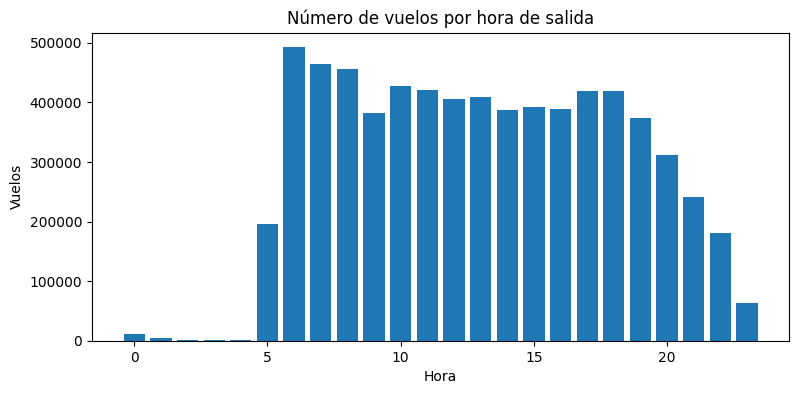

In [14]:
# Cuántos vuelos salen a cada hora
vuelos_hora = vuelos.groupBy("DepHour").count().orderBy("DepHour").toPandas()

madrugada = vuelos_hora[vuelos_hora["DepHour"] < 5]["count"].sum()
print(f"Vuelos de 0 a 4 am: {madrugada:,} ({madrugada / vuelos_hora['count'].sum() * 100:.2f}%)")

plt.figure(figsize=(9, 4))
plt.bar(vuelos_hora["DepHour"], vuelos_hora["count"])
plt.title("Número de vuelos por hora de salida")
plt.xlabel("Hora")
plt.ylabel("Vuelos")
plt.show()

Con respecto a la hora, el retraso va subiendo desde las 5 am (8.8%) hasta las 8 pm (29.8%), lo cual tiene sentido porque si un avión se atrasa, también se atrasan sus siguientes vuelos durante el día. La combinación más puntual es el martes a las 5 am con 7.8% y la peor es el domingo a las 8 pm con 33.8%. Los porcentajes de 0 a 4 am salen altos, pero no son muy confiables porque en esas horas sale solo el 0.26% de los vuelos, como se ve en la gráfica.

En cuanto a los meses, julio tiene casi 7% más vuelos que noviembre, pero más del doble de retraso (28.6% contra 13.6%) y también es el mes con más cancelaciones (2.43%). Esto nos dice que el aumento de retrasos en verano no se explica solo por tener más vuelos.

*Los datos por día y hora y por mes están en `agg_hora_dia.csv` y `agg_aerolinea_mes.csv` (sección 8).*

In [15]:
# Los 10 aeropuertos de origen con más vuelos y su % de retraso
(vuelos.groupBy("Origin", "OriginCityName")
 .agg(F.count("*").alias("vuelos"), F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retraso"))
 .orderBy(F.desc("vuelos"))
 .show(10, truncate=False))

+------+---------------------+------+-----------+
|Origin|OriginCityName       |vuelos|pct_retraso|
+------+---------------------+------+-----------+
|ATL   |Atlanta, GA          |336463|19.46      |
|DEN   |Denver, CO           |288985|25.69      |
|DFW   |Dallas/Fort Worth, TX|285244|23.99      |
|ORD   |Chicago, IL          |258867|22.02      |
|CLT   |Charlotte, NC        |195100|22.74      |
|LAX   |Los Angeles, CA      |194353|18.74      |
|LAS   |Las Vegas, NV        |190877|26.82      |
|PHX   |Phoenix, AZ          |176691|18.65      |
|MCO   |Orlando, FL          |164369|28.68      |
|SEA   |Seattle, WA          |163812|19.47      |
+------+---------------------+------+-----------+
only showing top 10 rows


De los 37 aeropuertos con 50 mil vuelos o más, los que tienen mayor retraso son Fort Lauderdale (31.3%), Orlando (28.7%), Miami (27.3%) y Las Vegas (26.8%), mientras que los mejores son Minneapolis (15.8%) y Portland (15.9%). Tres de los cuatro peores están en Florida, lo que nos podría indicar un problema de la región y no de un solo aeropuerto, aunque con estos datos no podemos comprobar la causa.

*Estos datos están en `agg_aeropuerto.csv` (sección 8).*

In [16]:
# Minutos totales de retraso por causa
causas = vuelos.select(
    F.sum("CarrierDelay").alias("Aerolínea"),
    F.sum("WeatherDelay").alias("Clima"),
    F.sum("NASDelay").alias("Sistema aéreo (NAS)"),
    F.sum("SecurityDelay").alias("Seguridad"),
    F.sum("LateAircraftDelay").alias("Avión llegó tarde"),
)
causas.show()

+-----------+---------+-------------------+---------+-----------------+
|  Aerolínea|    Clima|Sistema aéreo (NAS)|Seguridad|Avión llegó tarde|
+-----------+---------+-------------------+---------+-----------------+
|3.4862074E7|5009341.0|        1.7310028E7| 206677.0|      3.8310004E7|
+-----------+---------+-------------------+---------+-----------------+



De los 95.7 millones de minutos de retraso, el 40.0% se debe a que el avión llegó tarde, el 36.4% a la aerolínea, el 18.1% al sistema aéreo, el 5.2% al clima extremo y el 0.2% a seguridad. Las dos primeras causas juntas representan el 76%, por lo que la mayor parte de los retrasos se registra como un tema de operación.

Además, julio acumula casi 3 veces los minutos de noviembre (13.1 contra 4.5 millones), pero el porcentaje de "avión llegó tarde" se mantiene entre 37% y 43% todos los meses. Esto nos indica que en verano hay muchos más retrasos, pero las causas siguen siendo prácticamente las mismas.

*Los datos por mes están en `agg_causas.csv` (sección 8).*

### Gráficas
Spark hace los cálculos sobre todos los datos y solo paso a pandas los resultados, que son pocas filas, para poder graficarlos.

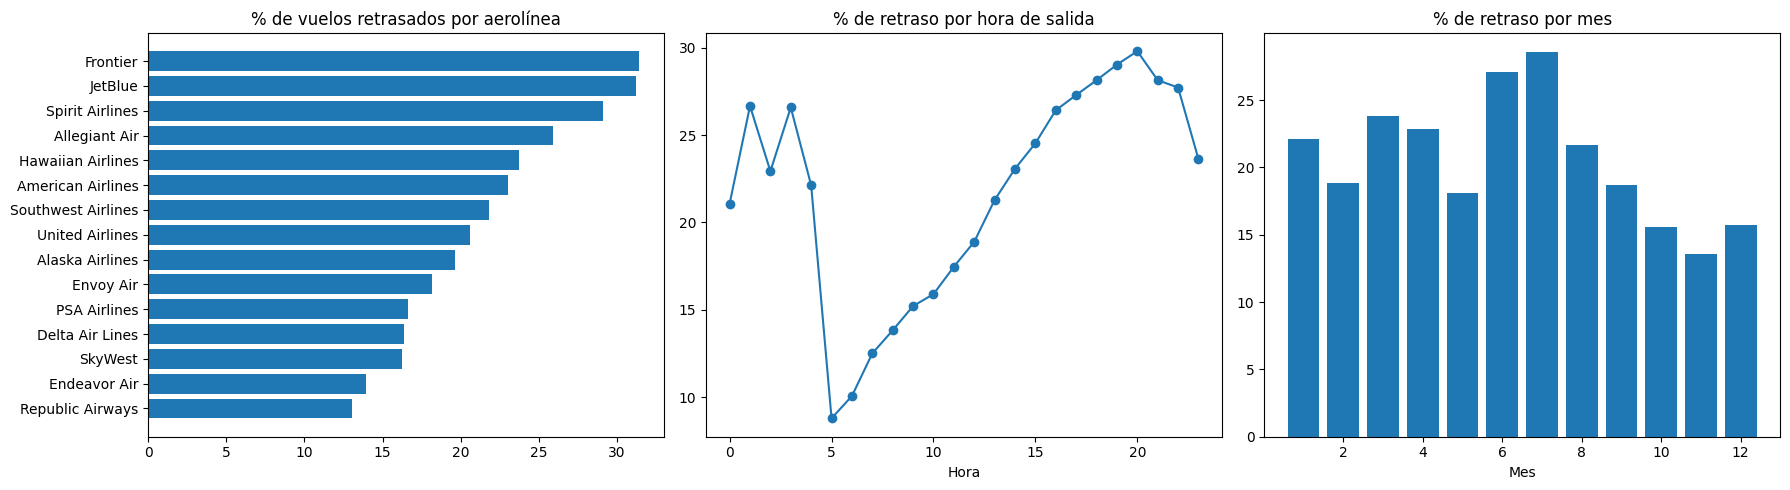

In [17]:
import matplotlib.pyplot as plt

pd_aero = por_aerolinea.toPandas()
pd_hora = por_hora.toPandas()
pd_mes = por_mes.toPandas()

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].barh(pd_aero["Airline"], pd_aero["pct_retraso"])
ax[0].set_title("% de vuelos retrasados por aerolínea")
ax[0].invert_yaxis()

ax[1].plot(pd_hora["DepHour"], pd_hora["pct_retraso"], marker="o")
ax[1].set_title("% de retraso por hora de salida")
ax[1].set_xlabel("Hora")

ax[2].bar(pd_mes["Month"], pd_mes["pct_retraso"])
ax[2].set_title("% de retraso por mes")
ax[2].set_xlabel("Mes")

plt.tight_layout()
plt.show()

### Lo que encontré
- El 20.6% de los vuelos llegó con retraso, el 1.3% se canceló y el 0.2% se desvió.
- Las aerolíneas con más retrasos son Frontier (31%), JetBlue (31%) y Spirit (29%). Las más puntuales son Republic (13%), Endeavor (14%) y Delta (16%).
- La hora es lo que más influye. A las 5 am se retrasa el 9% de los vuelos y a las 8 pm casi el 30%, porque los retrasos se van acumulando durante el día. Entre 0 y 4 am hay muy pocos vuelos, así que esos números no son tan confiables.
- Junio y julio son los peores meses (27% y 29%) y de octubre a diciembre los mejores (14% a 16%).
- De los aeropuertos grandes, Orlando, Las Vegas y Denver son los que más retrasos tienen.
- La causa principal es que el avión llegó tarde de su vuelo anterior, luego problemas de la aerolínea y luego el sistema aéreo. El clima extremo pesa poco (5.2% de los minutos), aunque esta categoría no incluye todo el clima, ya que el clima no extremo se registra dentro de NAS y parte también puede terminar como "avión llegó tarde".

## 4. Preparación de variables
Lo que quiero predecir es `ArrDel15`, que vale 1 si el vuelo llegó con 15 minutos o más de retraso y 0 si no.

Como variables uso solo cosas que se saben antes del vuelo: aerolínea, origen, destino, mes, día de la semana, hora de salida, día del mes y distancia. No uso el retraso real ni las causas, porque eso se sabe hasta después y sería hacer trampa.

Solo el 20% de los vuelos se retrasa. Si no hago nada, el modelo aprende a decir que ningún vuelo se retrasa y aun así acierta mucho. Para evitarlo le doy más peso a los vuelos retrasados.

In [18]:
datos = (vuelos
         .filter((F.col("Cancelled") == 0) & (F.col("Diverted") == 0) & F.col("ArrDel15").isNotNull())
         .select("Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour",
                 "DayofMonth", "Distance", F.col("ArrDel15").alias("label")))

proporcion = datos.filter(F.col("label") == 1).count() / datos.count()
print(f"Proporción de vuelos retrasados: {proporcion:.3f}")

# Peso: los retrasados (minoría) pesan más
datos = datos.withColumn("peso", F.when(F.col("label") == 1, 1 - proporcion).otherwise(proporcion))

Proporción de vuelos retrasados: 0.206


### División de los datos
Separo los datos en 70% para entrenar, 15% para comparar los modelos y escoger el mejor, y 15% para la prueba final con datos que el modelo nunca vio.

In [19]:
train, val, test = datos.randomSplit([0.7, 0.15, 0.15], seed=42)
train.cache()

print("Entrenamiento:", train.count())
print("Validación:   ", val.count())
print("Prueba:       ", test.count())

Entrenamiento: 4720388
Validación:    1011407
Prueba:        1011608


La división quedó en 70/15/15 sobre los 6,743,403 vuelos. Solo guardé en caché `train`, ya que es el que se recorre varias veces al entrenar, así Spark no tiene que volver a leer y transformar los datos en cada iteración.

## 5. Modelos
Armo un Pipeline con los pasos de preparación y el modelo, para que todo se aplique igual en entrenamiento, prueba y datos nuevos:
1. `StringIndexer` convierte las categorías en números.
2. `OneHotEncoder` convierte esos números en columnas de 0 y 1.
3. `VectorAssembler` junta todo en un solo vector.
4. El modelo.

Pruebo dos modelos: Regresión Logística, que es sencilla y rápida, y Random Forest, que usa muchos árboles de decisión.

In [20]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

categoricas = ["Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour"]
numericas = ["DayofMonth", "Distance"]

indexer = StringIndexer(inputCols=categoricas,
                        outputCols=[c + "_idx" for c in categoricas],
                        handleInvalid="keep")   # categorías nuevas no rompen el modelo
encoder = OneHotEncoder(inputCols=[c + "_idx" for c in categoricas],
                        outputCols=[c + "_vec" for c in categoricas])
assembler = VectorAssembler(inputCols=[c + "_vec" for c in categoricas] + numericas,
                            outputCol="features")

lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso", maxIter=20)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso",
                            numTrees=30, maxDepth=10, seed=42)

pipeline_lr = Pipeline(stages=[indexer, encoder, assembler, lr])
pipeline_rf = Pipeline(stages=[indexer, encoder, assembler, rf])

In [21]:
inicio = time.time()
modelo_lr = pipeline_lr.fit(train)
print(f"Regresión Logística entrenada en {time.time() - inicio:.0f} s")

inicio = time.time()
modelo_rf = pipeline_rf.fit(train)
print(f"Random Forest entrenado en {time.time() - inicio:.0f} s")

Regresión Logística entrenada en 101 s
Random Forest entrenado en 888 s


El Random Forest tardó aproximadamente 8.8 veces más que la Regresión Logística (888 s contra 101 s) con los mismos 4.7 millones de vuelos, por lo que con este volumen de datos el tiempo de entrenamiento sí es algo que hay que tomar en cuenta al elegir el modelo.

## 6. Evaluación
Para evaluar uso:
- AUC: qué tan bien separa los vuelos retrasados de los puntuales (0.5 es como adivinar y 1 es perfecto).
- Accuracy: porcentaje de aciertos.
- Precisión: de los vuelos que el modelo marca como retrasados, cuántos sí lo estaban.
- Recall: de los vuelos que sí se retrasaron, cuántos detectó.

### Comparación con validación

In [22]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

eval_auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
eval_multi = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

def metricas(predicciones):
    return {
        "AUC": eval_auc.evaluate(predicciones),
        "Accuracy": eval_multi.evaluate(predicciones, {eval_multi.metricName: "accuracy"}),
        "Precision (retraso)": eval_multi.evaluate(predicciones, {eval_multi.metricName: "precisionByLabel", eval_multi.metricLabel: 1.0}),
        "Recall (retraso)": eval_multi.evaluate(predicciones, {eval_multi.metricName: "recallByLabel", eval_multi.metricLabel: 1.0}),
        "F1 ponderado": eval_multi.evaluate(predicciones, {eval_multi.metricName: "f1"}),
    }

import pandas as pd

comparacion = pd.DataFrame({
    "Regresión Logística": metricas(modelo_lr.transform(val)),
    "Random Forest": metricas(modelo_rf.transform(val)),
}).round(4)
comparacion

,Regresión Logística,Random Forest
AUC,0.6730,0.6667
Accuracy,0.6169,0.6057
Precision (retraso),0.2989,0.2928
Recall (retraso),0.6423,0.6491
F1 ponderado,0.6533,0.6434


In [23]:
# Se elige el modelo con mejor AUC en validación
if comparacion.loc["AUC", "Random Forest"] >= comparacion.loc["AUC", "Regresión Logística"]:
    mejor_nombre, mejor_modelo = "Random Forest", modelo_rf
else:
    mejor_nombre, mejor_modelo = "Regresión Logística", modelo_lr

print("Mejor modelo:", mejor_nombre)

Mejor modelo: Regresión Logística


La Regresión Logística salió mejor en AUC, accuracy, precisión y F1, y el Random Forest solo la supera por poco en recall (64.9% contra 64.2%). Como además tarda mucho más en entrenar, en este caso no se justifica usar el modelo más complejo.

### Prueba final

In [24]:
pred_test = mejor_modelo.transform(test)
pred_test.cache()

resultado_test = pd.Series(metricas(pred_test)).round(4)
resultado_test

,0
AUC,0.6721
Accuracy,0.6168
Precision (retraso),0.2988
Recall (retraso),0.6414
F1 ponderado,0.6532


In [25]:
# Matriz de confusión
print("Filas = valor real, columnas = predicción")
pred_test.groupBy("label").pivot("prediction").count().orderBy("label").show()

Filas = valor real, columnas = predicción
+-----+------+------+
|label|   0.0|   1.0|
+-----+------+------+
|  0.0|490548|313080|
|  1.0| 74589|133391|
+-----+------+------+



En el conjunto de prueba el modelo detectó el 64% de los vuelos que sí se retrasaron. Cuando dice que un vuelo se va a retrasar acierta el 30% de las veces. Parece poco, pero solo el 20% de los vuelos se retrasa, así que es mejor que adivinar. También genera bastantes falsas alarmas (313 mil), que es el costo de detectar más retrasos, ya que por cada retraso bien detectado hay 2.3 falsas alarmas.

Hay que tener cuidado con el accuracy de 61.7%, ya que un modelo que siempre dijera "puntual" tendría 79.4%, pero no detectaría ningún retraso. El accuracy bajó porque balanceamos las clases, por lo que aquí nos fijamos más en el AUC, el recall y la precisión. Cuando el modelo marca un retraso acierta el 29.9% de las veces, contra el 20.6% de la tasa base, o sea 1.45 veces más.

### Variables más importantes (Random Forest)
Los nombres se leen así: `DepHour_vec_6` es salir a las 6 am, `Month_vec_11` es noviembre y `Reporting_Airline_vec_F9` es Frontier.

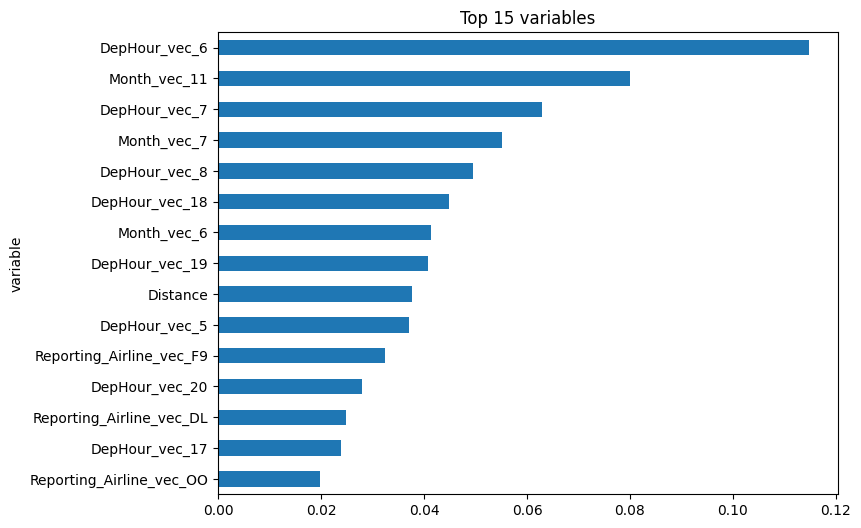

In [26]:
# Nombres de cada posición del vector "features"
attrs = modelo_rf.transform(val.limit(1)).schema["features"].metadata["ml_attr"]["attrs"]
nombres = {a["idx"]: a["name"] for grupo in attrs.values() for a in grupo}

importancias = modelo_rf.stages[-1].featureImportances.toArray()
top = (pd.DataFrame({"variable": [nombres.get(i, str(i)) for i in range(len(importancias))], "importancia": importancias})
       .sort_values("importancia", ascending=False).head(15))

top.plot.barh(x="variable", y="importancia", figsize=(8, 6), legend=False, title="Top 15 variables")
plt.gca().invert_yaxis()
plt.show()

De las 15 variables más importantes, 8 son horas de salida y 3 son meses, lo cual coincide con lo que vimos en el análisis. Hay que tomar en cuenta que esta importancia es del Random Forest y no del modelo final, y que solo nos dice cuánto ayuda cada variable, no si hace que el retraso suba o baje. También, como usé one-hot, la importancia se reparte entre las categorías, por lo que origen y destino, que tienen cientos de aeropuertos, pueden verse menos importantes de lo que son.

### Guardar el modelo
Guardo el modelo y lo vuelvo a cargar para comprobar que se puede reutilizar.

In [27]:
from pyspark.ml import PipelineModel

mejor_modelo.write().overwrite().save("/content/modelo_retrasos")
modelo_cargado = PipelineModel.load("/content/modelo_retrasos")
print("Modelo cargado correctamente:", [type(s).__name__ for s in modelo_cargado.stages])

Modelo cargado correctamente: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'LogisticRegressionModel']


## 7. Predicciones
### Con datos de prueba
`probabilidad_retraso` es el score de riesgo que da el modelo. Como entrené con pesos, nos sirve para ordenar los vuelos de mayor a menor riesgo, pero no es una probabilidad real, lo cual se muestra más abajo.

In [28]:
from pyspark.ml.functions import vector_to_array

pred_test = pred_test.withColumn("probabilidad_retraso", F.round(vector_to_array("probability")[1], 3))

pred_test.select("Reporting_Airline", "Origin", "Dest", "Month", "DepHour",
                 "label", "prediction", "probabilidad_retraso").show(15)

+-----------------+------+----+-----+-------+-----+----------+--------------------+
|Reporting_Airline|Origin|Dest|Month|DepHour|label|prediction|probabilidad_retraso|
+-----------------+------+----+-----+-------+-----+----------+--------------------+
|               9E|   ABE| ATL|    1|      6|  0.0|       0.0|               0.193|
|               9E|   ABE| ATL|    1|      6|  0.0|       0.0|               0.205|
|               9E|   ABE| ATL|    7|     12|  0.0|       0.0|               0.434|
|               9E|   ABE| ATL|    7|     12|  0.0|       0.0|               0.384|
|               9E|   ABE| ATL|    7|     12|  0.0|       0.0|               0.405|
|               9E|   ABE| ATL|    7|     12|  0.0|       0.0|               0.414|
|               9E|   ABE| ATL|    7|     17|  0.0|       1.0|               0.514|
|               9E|   ABE| ATL|    7|     17|  0.0|       1.0|               0.532|
|               9E|   ABE| ATL|    7|      6|  0.0|       0.0|              

Aquí podemos ver que en la ruta ABE→ATL de julio el score va subiendo con la hora, con alrededor de 0.25 a las 6 am, entre 0.38 y 0.46 a las 12 y entre 0.51 y 0.56 a las 5 pm, por lo que el modelo sí capturó el efecto de la hora. Sin embargo, vuelos con las mismas características tienen resultados distintos, ya que con datos de calendario y ruta el modelo no puede saber qué pasó ese día en particular.

### Con vuelos inventados
Invento 5 vuelos y los predigo con el modelo que acabo de cargar.

In [29]:
nuevos = spark.createDataFrame([
    ("AA", "ORD", "LAX", 12, 5, 18, 22, 1744.0),   # American, Chicago→LA, viernes de diciembre 18:00
    ("DL", "ATL", "JFK",  3, 2,  7, 14,  760.0),   # Delta, Atlanta→NY, martes de marzo 7:00
    ("WN", "LAS", "DEN",  7, 7, 20,  9,  628.0),   # Southwest, Las Vegas→Denver, domingo de julio 20:00
    ("UA", "SFO", "EWR",  1, 3,  6, 11, 2565.0),   # United, San Francisco→Newark, miércoles de enero 6:00
    ("NK", "FLL", "MCO",  6, 6, 21, 24,  177.0),   # Spirit, Fort Lauderdale→Orlando, sábado de junio 21:00
], ["Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour", "DayofMonth", "Distance"])

(modelo_cargado.transform(nuevos)
 .withColumn("probabilidad_retraso", F.round(vector_to_array("probability")[1], 3))
 .select("Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour",
         "prediction", "probabilidad_retraso")
 .show())

+-----------------+------+----+-----+---------+-------+----------+--------------------+
|Reporting_Airline|Origin|Dest|Month|DayOfWeek|DepHour|prediction|probabilidad_retraso|
+-----------------+------+----+-----+---------+-------+----------+--------------------+
|               AA|   ORD| LAX|   12|        5|     18|       1.0|               0.621|
|               DL|   ATL| JFK|    3|        2|      7|       0.0|               0.343|
|               WN|   LAS| DEN|    7|        7|     20|       1.0|               0.808|
|               UA|   SFO| EWR|    1|        3|      6|       0.0|                0.36|
|               NK|   FLL| MCO|    6|        6|     21|       1.0|               0.823|
+-----------------+------+----+-----+---------+-------+----------+--------------------+



 score  vuelos  pct_real
   0.1    1240       6.0
   0.2    5531       9.1
   0.3    9630      11.8
   0.4   11770      16.6
   0.5   11251      23.1
   0.6    7773      32.6
   0.7    2952      44.4
   0.8     239      61.1


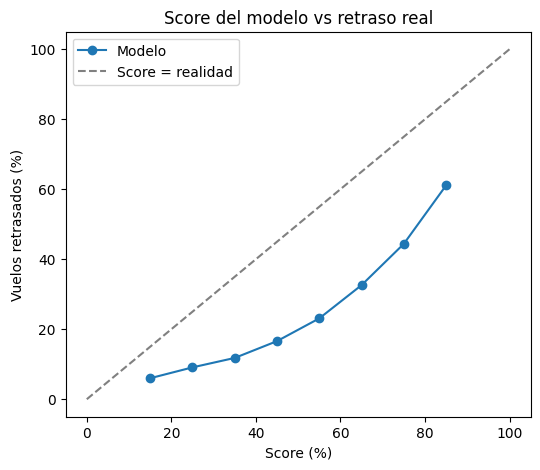

In [30]:
# Comparo el score del modelo contra lo que pasó en realidad (muestra del 5%)
calibracion = (pred_test.sample(fraction=0.05, seed=42)
               .withColumn("score", F.floor(F.col("probabilidad_retraso") * 10) / 10)
               .groupBy("score")
               .agg(F.count("*").alias("vuelos"),
                    F.round(F.avg("label") * 100, 1).alias("pct_real"))
               .filter(F.col("vuelos") >= 100)
               .orderBy("score")
               .toPandas())
print(calibracion.to_string(index=False))

plt.figure(figsize=(6, 5))
plt.plot((calibracion["score"] + 0.05) * 100, calibracion["pct_real"], marker="o", label="Modelo")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Score = realidad")
plt.title("Score del modelo vs retraso real")
plt.xlabel("Score (%)")
plt.ylabel("Vuelos retrasados (%)")
plt.legend()
plt.show()

Los resultados tienen sentido, ya que los vuelos de noche en verano (Spirit con 0.82 y Southwest con 0.81) salen con más riesgo que los de la mañana (Delta con 0.34 y United con 0.36). El de American sale con 0.62 aunque diciembre es de los meses con menos retraso, lo cual se puede deber a que sale a las 6 pm.

Aquí es importante aclarar que estos scores no son probabilidades reales. Como le di más peso a los vuelos retrasados, el modelo aprende como si la mitad de los vuelos se retrasara, cuando en realidad es el 20.6%. En la tabla y la gráfica de arriba podemos ver que el retraso real sí sube conforme sube el score, por lo que el modelo sirve para identificar qué vuelos tienen más riesgo, pero el vuelo de Spirit con 0.82 está en un grupo que se retrasó cerca del 61% de las veces y no el 82%.

## 8. Datos para Tableau
No tiene caso subir casi 7 millones de filas a Tableau, así que con Spark resumo los datos en tablas pequeñas y las exporto a CSV:
- `agg_aerolinea_mes.csv`: datos por aerolínea y mes
- `agg_aeropuerto.csv`: datos por aeropuerto (para el mapa)
- `agg_hora_dia.csv`: retraso por hora y día de la semana
- `agg_causas.csv`: minutos de retraso por causa y mes
- `predicciones_muestra.csv`: una muestra de las predicciones
- `metricas_modelo.csv`: resultados del modelo

In [31]:
os.makedirs("/content/tableau", exist_ok=True)

def indicadores():
    return [F.count("*").alias("vuelos"),
            F.round(F.avg("ArrDel15") * 100, 2).alias("pct_retraso"),
            F.round(F.avg("ArrDelay"), 2).alias("retraso_promedio_min"),
            F.round(F.avg("Cancelled") * 100, 2).alias("pct_cancelados")]

vuelos.groupBy("Airline", "Month").agg(*indicadores()) \
    .toPandas().to_csv("/content/tableau/agg_aerolinea_mes.csv", index=False)

vuelos.groupBy("Origin", "OriginCityName").agg(*indicadores()) \
    .toPandas().to_csv("/content/tableau/agg_aeropuerto.csv", index=False)

vuelos.groupBy("DayOfWeek", "DepHour").agg(*indicadores()) \
    .toPandas().to_csv("/content/tableau/agg_hora_dia.csv", index=False)

(vuelos.groupBy("Month")
 .agg(F.sum("CarrierDelay").alias("Aerolínea"), F.sum("WeatherDelay").alias("Clima"),
      F.sum("NASDelay").alias("Sistema aéreo (NAS)"), F.sum("SecurityDelay").alias("Seguridad"),
      F.sum("LateAircraftDelay").alias("Avión llegó tarde"))
 .toPandas()
 .melt(id_vars="Month", var_name="causa", value_name="minutos")
 .to_csv("/content/tableau/agg_causas.csv", index=False))

(pred_test.sample(fraction=0.05, seed=42)
 .select("Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour",
         "label", "prediction", "probabilidad_retraso")
 .toPandas().to_csv("/content/tableau/predicciones_muestra.csv", index=False))

resultado_test.rename("valor").rename_axis("metrica").reset_index() \
    .to_csv("/content/tableau/metricas_modelo.csv", index=False)

!ls -lh /content/tableau

total 1.6M
-rw-r--r-- 1 root root 6.9K Nov 22 01:01 agg_aerolinea_mes.csv
-rw-r--r-- 1 root root  15K Nov 22 01:01 agg_aeropuerto.csv
-rw-r--r-- 1 root root 1.5K Nov 22 01:01 agg_causas.csv
-rw-r--r-- 1 root root 4.4K Nov 22 01:01 agg_hora_dia.csv
-rw-r--r-- 1 root root  112 Nov 22 01:01 metricas_modelo.csv
-rw-r--r-- 1 root root 1.6M Nov 22 01:01 predicciones_muestra.csv


Con Spark pasamos de 6.8 millones de filas a tablas de 5 a 350 filas, más una muestra de 50,396 predicciones (5% del conjunto de prueba). Todo junto pesa 1.6 MB, por lo que Tableau puede cargarlo sin problema y el trabajo pesado se queda en Spark.

In [32]:
# Descargar todos los CSV en un solo zip
!cd /content && zip -q -r tableau_datos.zip tableau
from google.colab import files
files.download("/content/tableau_datos.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Tablero
Enlace: https://public.tableau.com/app/profile/emilio.santiago.l.pez.qui.onez/viz/Tablero_Retrasos/DashboardRetrasos

Captura:

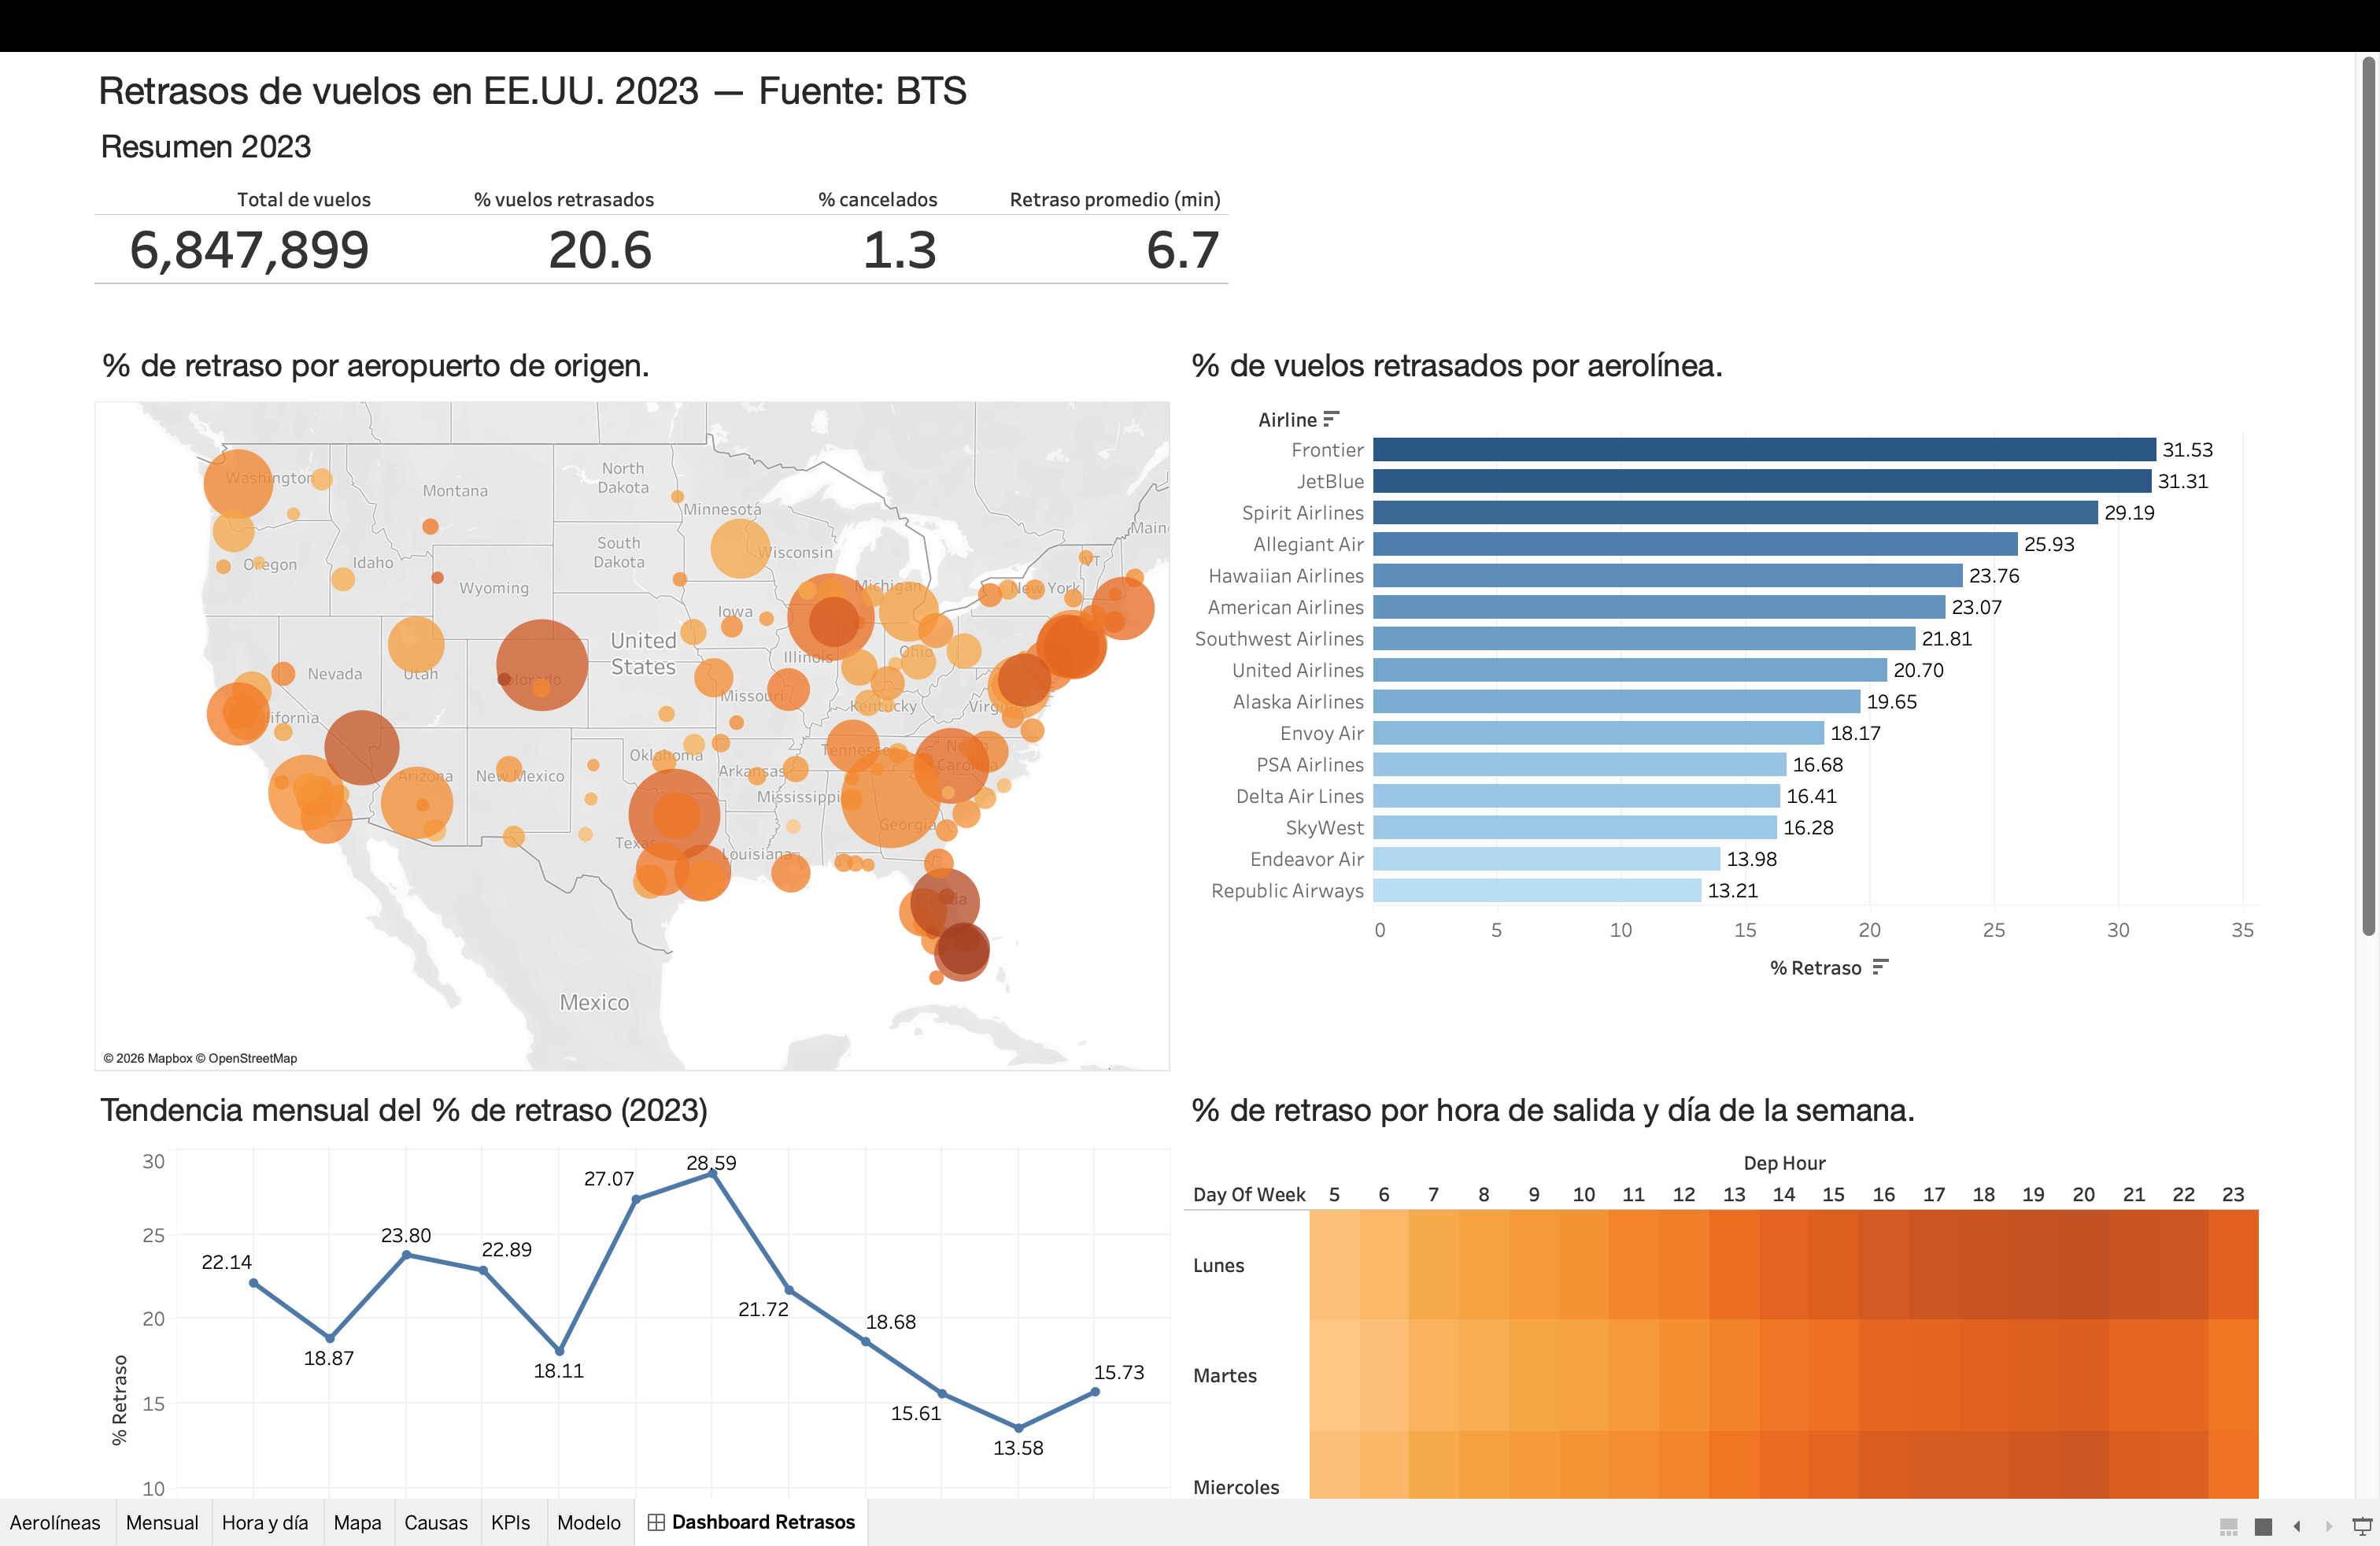

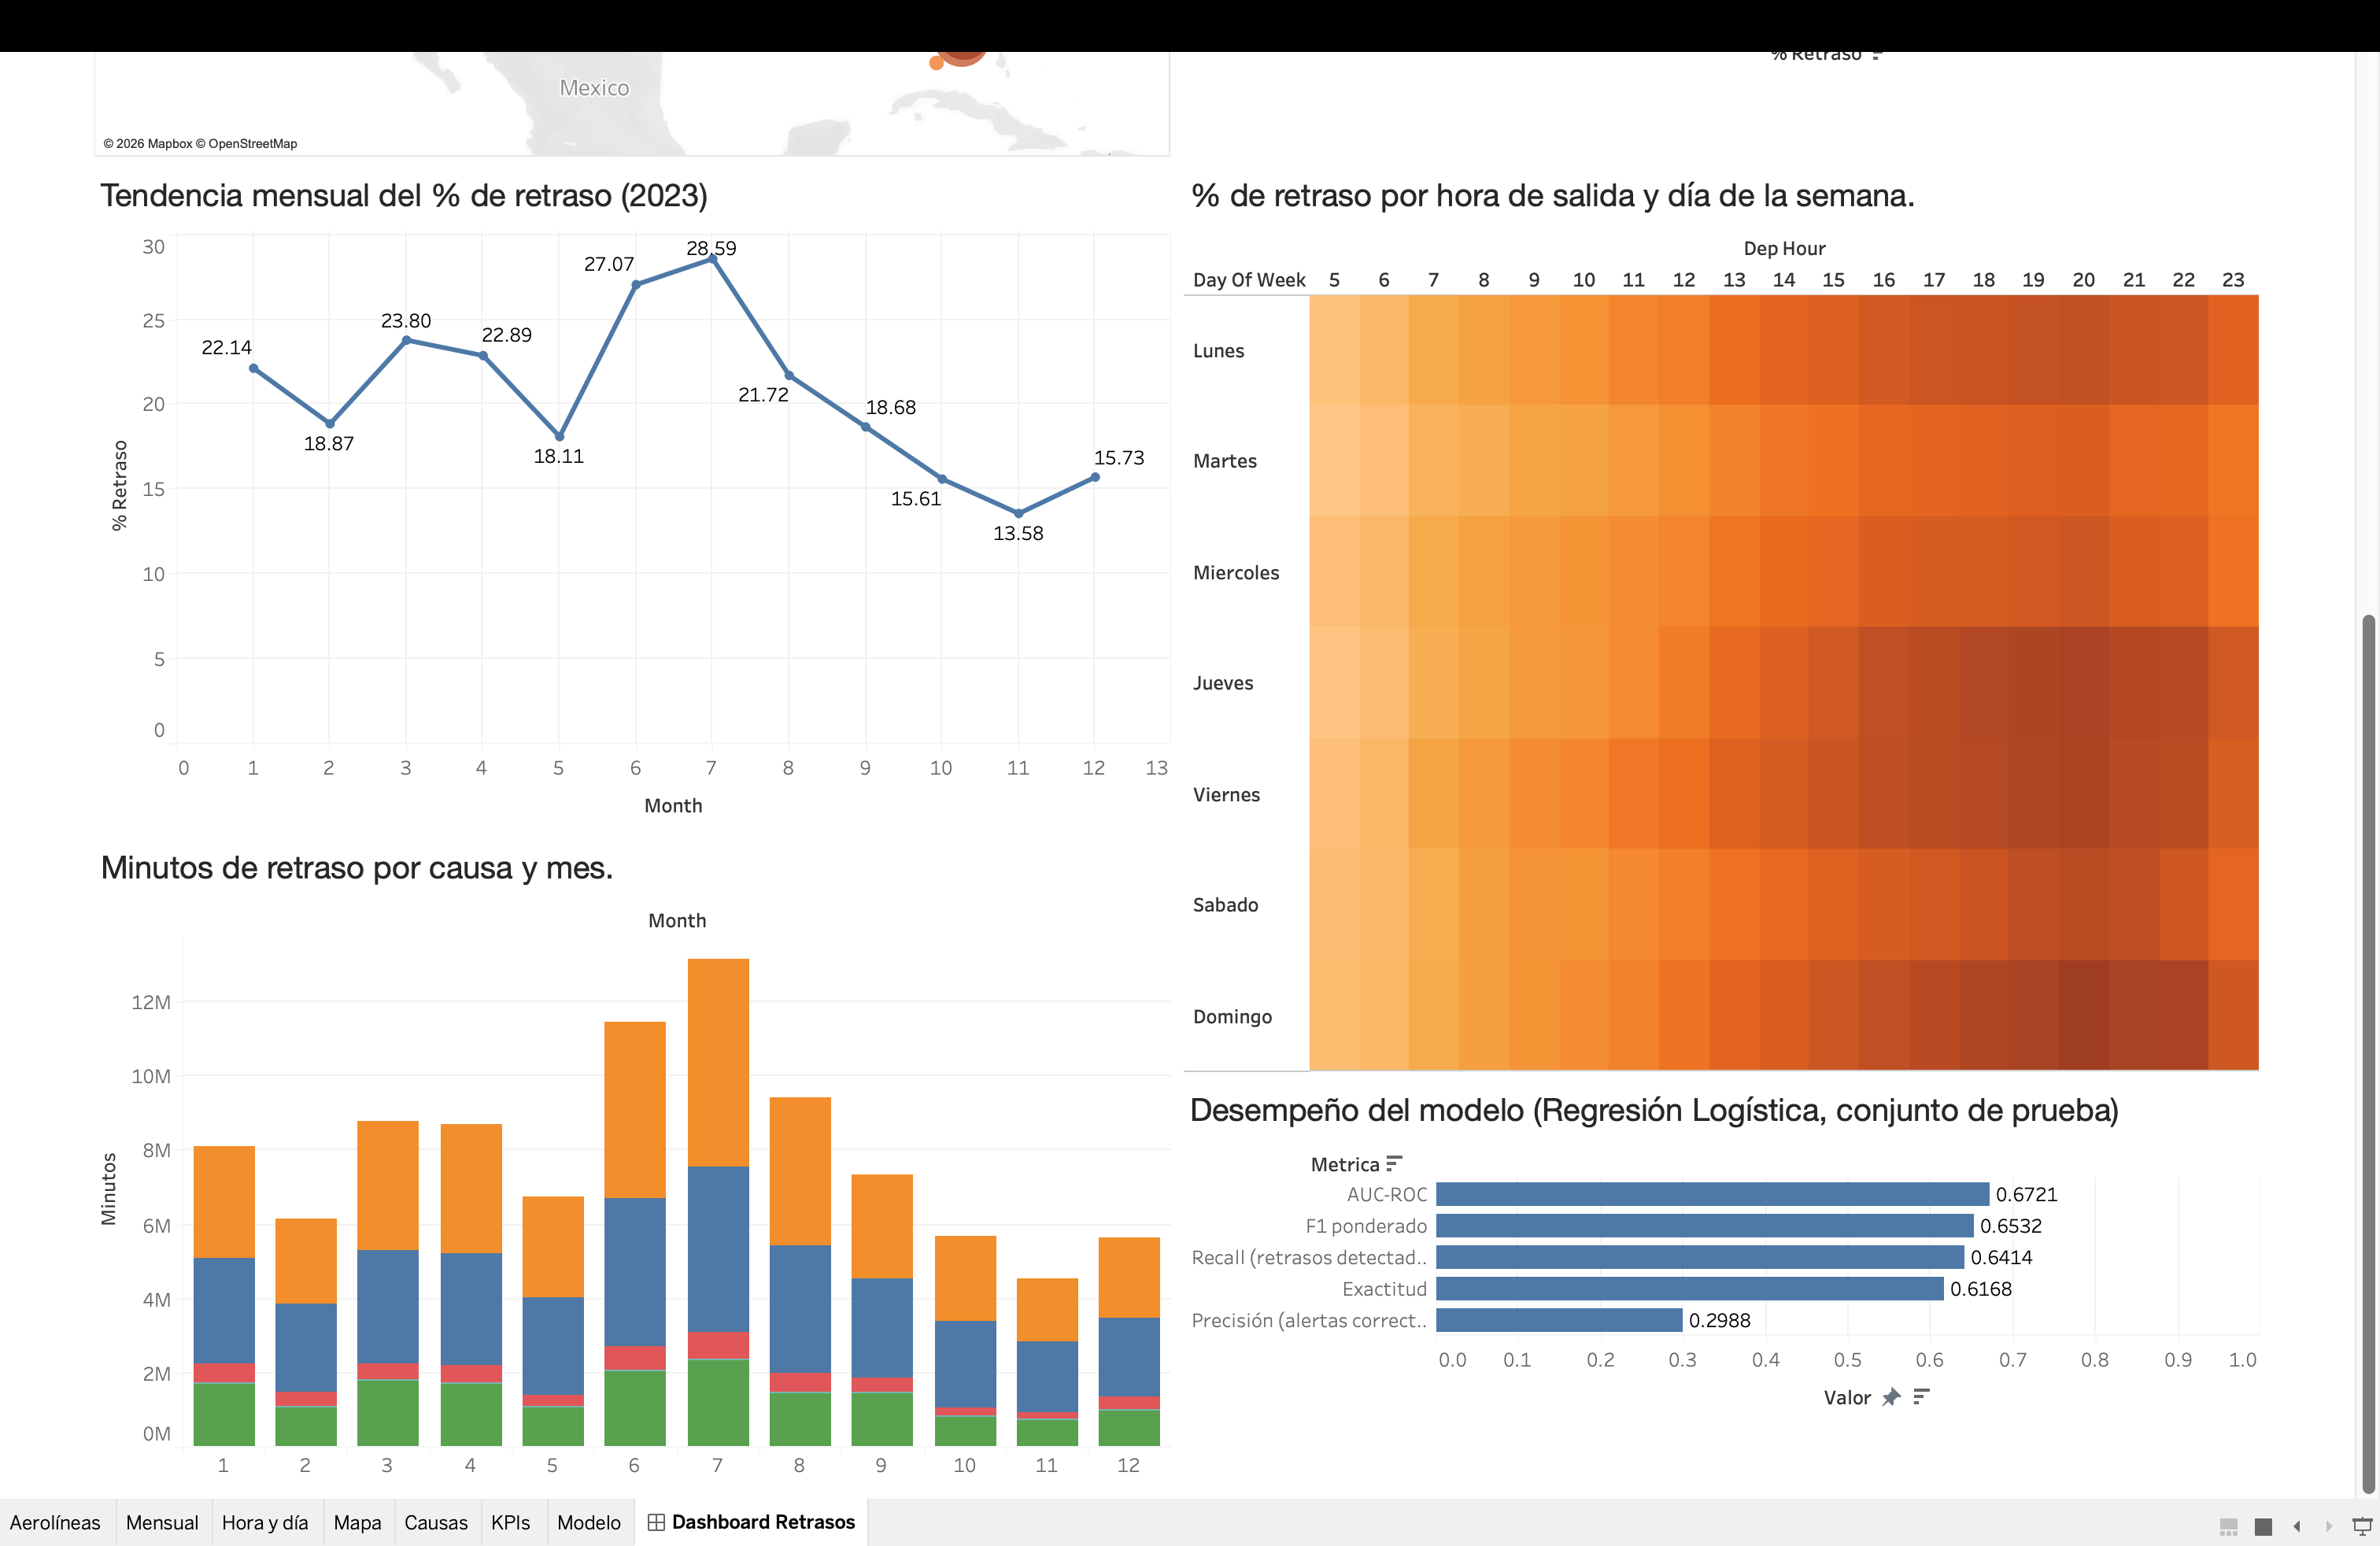

Cargué los CSV en Tableau, hice 7 gráficas, las junté en un dashboard y lo publiqué en Tableau Public. El tablero muestra:
- Indicadores generales: total de vuelos, % de retrasos, % de cancelados y retraso promedio.
- Un mapa con el % de retraso por aeropuerto.
- El % de retraso por aerolínea.
- La tendencia por mes.
- Un mapa de calor por hora y día de la semana.
- Las causas de los retrasos.
- Los resultados del modelo.

Con esto se puede ver, por ejemplo, que conviene programar los vuelos importantes temprano, reforzar personal en verano y en aeropuertos como Orlando o Denver, y cuidar que los aviones no lleguen tarde de su vuelo anterior.

## 10. Conclusiones
Pude procesar casi 7 millones de vuelos con PySpark directo desde la fuente oficial. Pasar los datos a Parquet hizo que las consultas fueran unas 17 veces más rápidas, y Spark hizo todo el trabajo pesado. A pandas y a Tableau solo les llegaron resúmenes pequeños.

Entrené una Regresión Logística y un Random Forest. Los dos dieron resultados muy parecidos (AUC de 0.673 y 0.667), pero la Regresión Logística entrenó en 101 segundos y el Random Forest en casi 15 minutos, así que me quedé con la primera. En la prueba final sacó un AUC de 0.672 y detectó el 64% de los retrasos. Los resultados de validación y prueba salieron casi iguales, lo que nos indica que el desempeño es estable con datos nuevos, aunque para descartar el sobreajuste también tendría que compararlo contra la métrica de entrenamiento.

Según el Random Forest, lo que más influye en los retrasos es la hora de salida y el mes. Las predicciones ordenan bien el riesgo, ya que un vuelo de Spirit en junio a las 9 pm tiene un score de 0.82 y uno de Delta en marzo a las 7 am de 0.34. Como entrené con pesos, ese score no es una probabilidad real, ya que en la muestra los vuelos con score de 0.8 a 0.9 se retrasaron el 61% de las veces.

También vimos que no basta con ver una sola métrica, ya que Frontier tiene el mayor porcentaje de retraso, pero Southwest concentra cerca del 22% de todos los retrasos por su volumen, y Republic es la más puntual, pero también la que más cancela (2.76%).

El modelo no es muy preciso porque solo usa datos de calendario y ruta. Para mejorarlo se podrían agregar datos del clima o del retraso del vuelo anterior del mismo avión, probar otros modelos como GBT y calibrar el score para que se pueda leer como probabilidad.